# Project 1: model comparison


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import create_csv_submission
from implementations import reg_logistic_regression, ROC_AUC
from learned_preprocess import fit, transform

## 1. Load

In [ ]:
CLEAN_DIR = "data/clean/"

x_train  = np.load(CLEAN_DIR + "x_train_clean.npy")
x_test   = np.load(CLEAN_DIR + "x_test_clean.npy")
y_train  = np.load(CLEAN_DIR + "y_train.npy")       # -1 / +1
test_ids = np.load(CLEAN_DIR + "test_ids.npy")
with open(CLEAN_DIR + "columns.txt") as f:
    names = f.read().splitlines()

y = (y_train == 1).astype(float)                    # 0 / 1
print("x_train:", x_train.shape, " positives:", f"{y.mean():.1%}")

x_train: (328135, 42)  positives: 8.8%


## 2. Helpers

In [ ]:
def sigmoid(z):
    return 0.5 * (1 + np.tanh(0.5 * z))

def f1_score(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    if tp == 0:
        return 0.0
    p, r = tp / (tp + fp), tp / (tp + fn)
    return 2 * p * r / (p + r)

def best_threshold(y_true, scores, grid=np.arange(0.05, 0.95, 0.01)):
    f1s = [f1_score(y_true, (scores >= t).astype(float)) for t in grid]
    return grid[int(np.argmax(f1s))], max(f1s)

## 3. Folds 

`fit` uses the training part of each fold only. All models reuse these matrices.

In [ ]:
K, SEED = 5, 42
rng = np.random.default_rng(SEED)
parts = np.array_split(rng.permutation(len(y)), K)

folds = []
for i in range(K):
    va = parts[i]
    tr = np.concatenate([parts[j] for j in range(K) if j != i])
    params = fit(x_train[tr], names)
    X_tr, feat_names = transform(x_train[tr], params)
    X_va, _          = transform(x_train[va], params)
    folds.append((X_tr, y[tr], X_va, y[va]))
print("Folds ready. Features per fold:", folds[0][0].shape[1])

Folds ready. Features per fold: 87


## 4. Evaluation and plotting functions

In [ ]:
results = {}
oof = {}   # name -> (pooled scores, pooled labels)

def evaluate(name, model, show=True):
    aucs, f1s, thrs = [], [], []
    sc, lab = [], []
    for X_tr, y_tr, X_va, y_va in folds:
        score = model(X_tr, y_tr, X_va)
        _, _, auc = ROC_AUC(y_va, score)
        t, f1 = best_threshold(y_va, score)
        aucs.append(auc)
        f1s.append(f1)
        thrs.append(t)
        sc.append(score)
        lab.append(y_va)
    results[name] = (np.mean(aucs), np.mean(f1s), np.mean(thrs))
    oof[name] = (np.concatenate(sc), np.concatenate(lab))
    if show:
        show_results()

def show_results():
    print(f"{'model':<35}{'AUC':>8}{'F1':>8}{'thr':>6}")
    for n, (a, f, t) in sorted(results.items(), key=lambda kv: -kv[1][0]):
        print(f"{n:<35}{a:>8.4f}{f:>8.4f}{t:>6.2f}")

def plot_performance(names, grid=np.arange(0.05, 0.80, 0.01)):
    """ROC curve and F1 against threshold for models already run with evaluate().
    names: list of model names used in evaluate()."""
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    for name in names:
        sc, lab = oof[name]
        fpr, tpr, auc = ROC_AUC(lab, sc)
        f1s = [f1_score(lab, (sc >= t).astype(float)) for t in grid]
        t_best = grid[int(np.argmax(f1s))]
        ax[0].plot(fpr, tpr, label=f"{name} (AUC {auc:.3f})")
        ax[1].plot(grid, f1s, label=f"{name} (thr {t_best:.2f}, F1 {max(f1s):.3f})")
    ax[0].plot([0, 1], [0, 1], "--", color="gray")
    ax[0].set_xlabel("false positive rate")
    ax[0].set_ylabel("true positive rate")
    ax[0].set_title("ROC (out-of-fold)")
    ax[0].legend(fontsize=8)
    ax[1].set_xlabel("threshold")
    ax[1].set_ylabel("F1")
    ax[1].set_title("F1 against threshold")
    ax[1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

def plot_sweep(values, name_fn, xlabel, log_x=True):
    """AUC and F1 against one hyperparameter."""
    auc = [results[name_fn(v)][0] for v in values]
    f1  = [results[name_fn(v)][1] for v in values]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    for a, yv, lab in zip(ax, (auc, f1), ("CV AUC", "CV F1")):
        (a.semilogx if log_x else a.plot)(values, yv, "o-")
        a.set_xlabel(xlabel)
        a.set_ylabel(lab)
    plt.tight_layout()
    plt.show()

## Model 1: regularized logistic regression

In [ ]:
MAX_ITERS, GAMMA = 300, 0.1

def model_rl(X_tr, y_tr, X_va, lam=1e-4, iters=MAX_ITERS, gamma=GAMMA):
    w, _ = reg_logistic_regression(y_tr, X_tr, lam, np.zeros(X_tr.shape[1]), iters, gamma)
    return sigmoid(X_va @ w)

evaluate("reg logistic (lam=1e-4)", model_rl)

model                                   AUC      F1   thr
reg logistic (lam=1e-4)              0.8522  0.4129  0.20


### Model 1: hyperparameters

In [ ]:
lambdas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
for lam in lambdas:
    evaluate(f"rl lam={lam:g}", lambda X, y, V, lam=lam: model_rl(X, y, V, lam=lam), show=False)

iters_list = [100, 300, 1000]
for it in iters_list:
    evaluate(f"rl lam=1e-4 iters={it}", lambda X, y, V, it=it: model_rl(X, y, V, iters=it), show=False)

show_results()

model                                   AUC      F1   thr
rl lam=1e-4 iters=1000               0.8536  0.4154  0.19
rl lam=1e-06                         0.8522  0.4128  0.20
rl lam=1e-05                         0.8522  0.4128  0.20
reg logistic (lam=1e-4)              0.8522  0.4129  0.20
rl lam=0.0001                        0.8522  0.4129  0.20
rl lam=1e-4 iters=300                0.8522  0.4129  0.20
rl lam=0.001                         0.8522  0.4124  0.21
rl lam=0.01                          0.8516  0.4111  0.23
rl lam=1e-4 iters=100                0.8495  0.4060  0.26
rl lam=0.1                           0.8462  0.3978  0.37


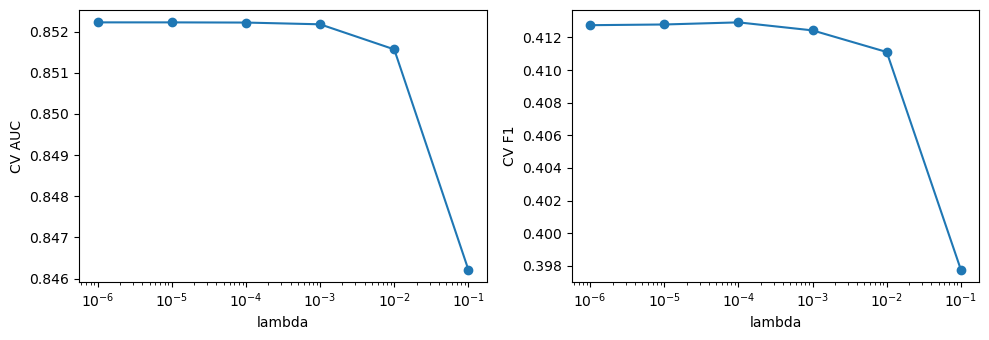

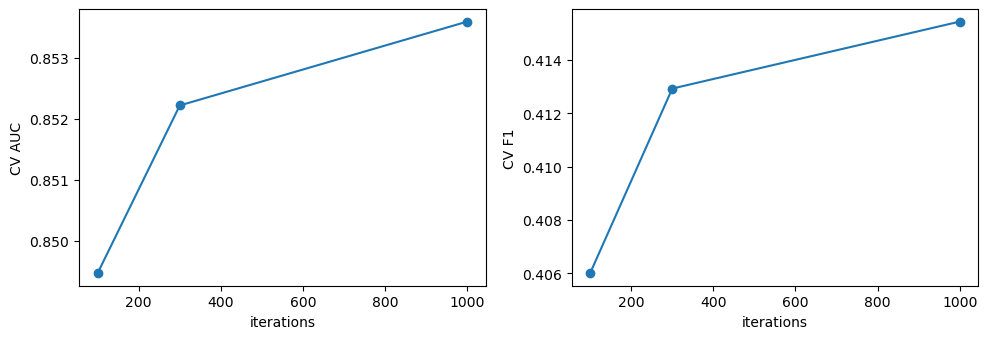

In [ ]:
plot_sweep(lambdas, lambda v: f"rl lam={v:g}", "lambda")
plot_sweep(iters_list, lambda v: f"rl lam=1e-4 iters={v}", "iterations", log_x=False)

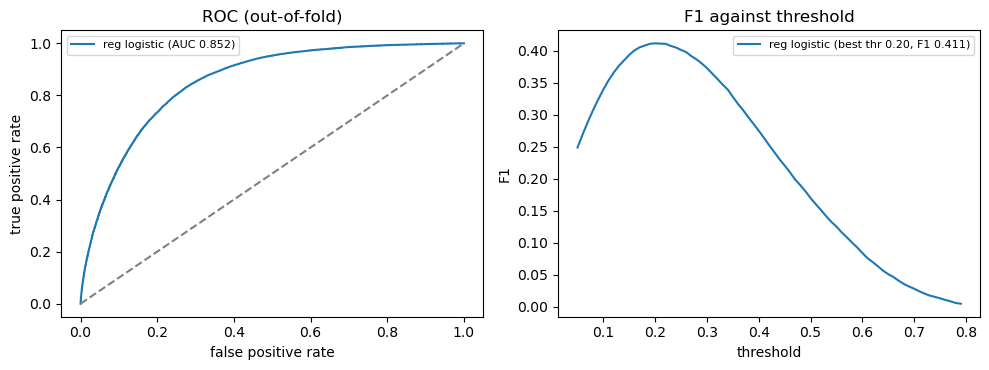

In [ ]:
plot_performance({"reg logistic": model_rl})

In [ ]:
for k in ["reg logistic (lam=1e-4)", "rl lam=0.0001"]:
    results.pop(k, None)

## Model 2 : Squares

model                                   AUC      F1   thr
rl lam=1e-4 iters=1000               0.8536  0.4154  0.19
rl + squares (lam=1e-4)              0.8526  0.4132  0.21
rl lam=1e-06                         0.8522  0.4128  0.20
rl lam=1e-05                         0.8522  0.4128  0.20
rl lam=1e-4 iters=300                0.8522  0.4129  0.20
rl lam=0.001                         0.8522  0.4124  0.21
rl lam=0.01                          0.8516  0.4111  0.23
rl lam=1e-4 iters=100                0.8495  0.4060  0.26
rl lam=0.1                           0.8462  0.3978  0.37


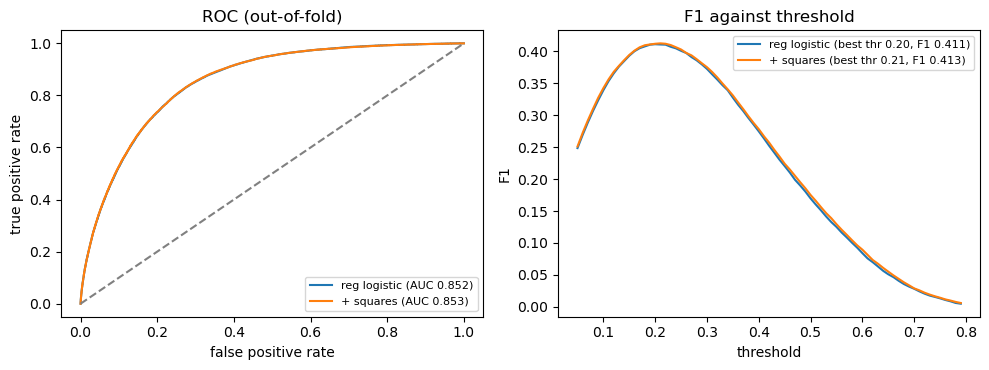

In [ ]:
def model_squares(X_tr, y_tr, X_va, lam=1e-4, iters=MAX_ITERS, gamma=GAMMA):
    cont = [j for j in range(1, X_tr.shape[1]) if len(np.unique(X_tr[:, j])) > 10]
    sq_tr, sq_va = X_tr[:, cont] ** 2, X_va[:, cont] ** 2
    mu, sd = sq_tr.mean(axis=0), sq_tr.std(axis=0) + 1e-8      # train statistics only
    A_tr = np.c_[X_tr, (sq_tr - mu) / sd]
    A_va = np.c_[X_va, (sq_va - mu) / sd]
    w, _ = reg_logistic_regression(y_tr, A_tr, lam, np.zeros(A_tr.shape[1]), iters, gamma)
    return sigmoid(A_va @ w)

evaluate("rl + squares (lam=1e-4)", model_squares)
plot_performance({"reg logistic": model_rl, "+ squares": model_squares})

In [ ]:
evaluate("rl + squares (1000 iters)", lambda X, y, V: model_squares(X, y, V, iters=1000))

model                                   AUC      F1   thr
rl + squares (1000 iters)            0.8540  0.4158  0.18
rl lam=1e-4 iters=1000               0.8536  0.4154  0.19
rl + squares (lam=1e-4)              0.8526  0.4132  0.21
rl lam=1e-06                         0.8522  0.4128  0.20
rl lam=1e-05                         0.8522  0.4128  0.20
rl lam=1e-4 iters=300                0.8522  0.4129  0.20
rl lam=0.001                         0.8522  0.4124  0.21
rl lam=0.01                          0.8516  0.4111  0.23
rl lam=1e-4 iters=100                0.8495  0.4060  0.26
rl lam=0.1                           0.8462  0.3978  0.37


AttributeError: 'list' object has no attribute 'items'

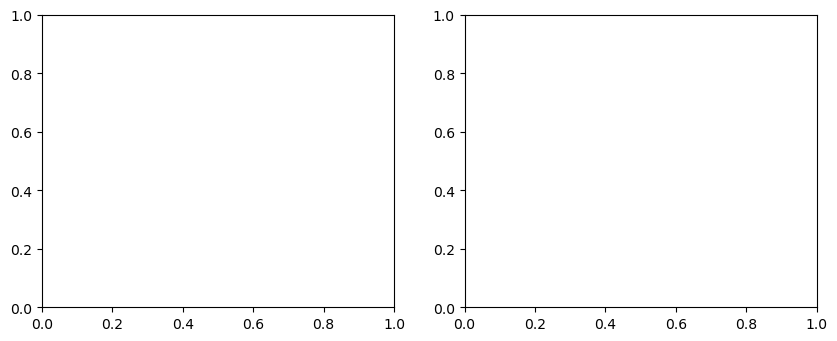

In [ ]:
plot_performance(["rl lam=1e-4 iters=1000", "rl + squares (1000 iters)"])